In [238]:
import sys

print("Python Version:", sys.version)
print("Google Colab is ready!")

Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Google Colab is ready!


In [239]:
!pip install -q ultralytics scikit-image

import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage
import ultralytics

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Scikit-image:", skimage.__version__)
print("YOLO:", ultralytics.__version__)

print("\nAll Computer Vision libraries are ready!")

OpenCV: 4.14.0
NumPy: 2.4.6
Matplotlib: 3.10.0
Scikit-image: 0.25.2
YOLO: 8.4.202

All Computer Vision libraries are ready!


In [240]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [241]:
import os

# Main project folder
project_path = "/content/drive/MyDrive/CCA3_Computer_Vision"

# Required folders
folders = [
    "dataset",
    "outputs/task1_image_restoration",
    "outputs/task1_segmentation",
    "outputs/task2_feature_extraction",
    "outputs/task3_object_detection",
    "outputs/task4_motion_estimation",
    "src",
    "documentation"
]

# Create folders
for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("Project folders created successfully!")

# Display folder locations
for folder in folders:
    print("Created:", folder)

Project folders created successfully!
Created: dataset
Created: outputs/task1_image_restoration
Created: outputs/task1_segmentation
Created: outputs/task2_feature_extraction
Created: outputs/task3_object_detection
Created: outputs/task4_motion_estimation
Created: src
Created: documentation


In [242]:
!pip install -q pillow-heif

import os
from PIL import Image
from pillow_heif import register_heif_opener

register_heif_opener()

dataset_path = "/content/drive/MyDrive/CCA3_Computer_Vision/dataset"

# Convert first photograph
img1 = Image.open(os.path.join(dataset_path, "Cv photo.HEIC"))
img1.convert("RGB").save(os.path.join(dataset_path, "original_photo.jpg"))

# Convert second photograph
img2 = Image.open(os.path.join(dataset_path, "Cv photo 2.HEIC"))
img2.convert("RGB").save(os.path.join(dataset_path, "second_photo.jpg"))

print("Both photographs converted successfully!")
print("Original photo:", img1.size)
print("Second photo:", img2.size)

Both photographs converted successfully!
Original photo: (3024, 4032)
Second photo: (3024, 4032)


In [243]:
import cv2
import os

video_path = "/content/drive/MyDrive/CCA3_Computer_Vision/dataset/Cv video.MOV"

cap = cv2.VideoCapture(video_path)

if cap.isOpened():
    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    print("Video opened successfully!")
    print("Resolution:", width, "x", height)
    print("FPS:", fps)
    print("Total frames:", frames)
    print("Duration:", round(frames/fps, 2), "seconds")
else:
    print("Video could not be opened.")

cap.release()

Video opened successfully!
Resolution: 1080 x 1920
FPS: 29.99345121152587
Total frames: 229
Duration: 7.63 seconds


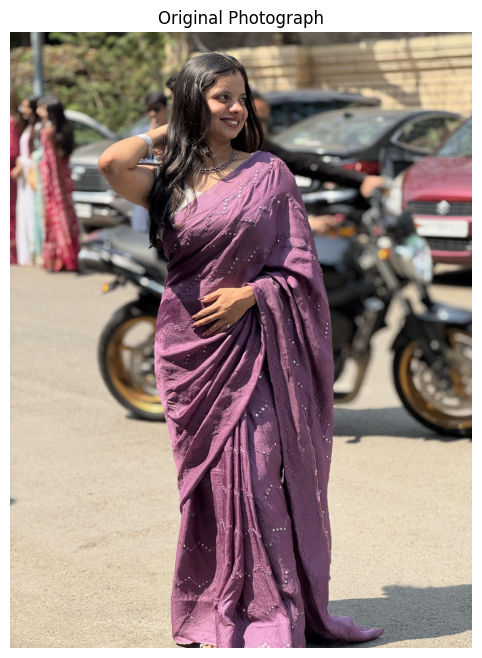

Image loaded successfully!
Image dimensions: (4032, 3024, 3)


In [244]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Dataset and output paths
dataset_path = "/content/drive/MyDrive/CCA3_Computer_Vision/dataset"
output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task1_image_restoration"

# Load original photograph
image = cv2.imread(os.path.join(dataset_path, "original_photo.jpg"))

# Convert BGR to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display original photograph
plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.title("Original Photograph")
plt.axis("off")
plt.show()

print("Image loaded successfully!")
print("Image dimensions:", image.shape)

Gussain Node
Salt and Paper Noise

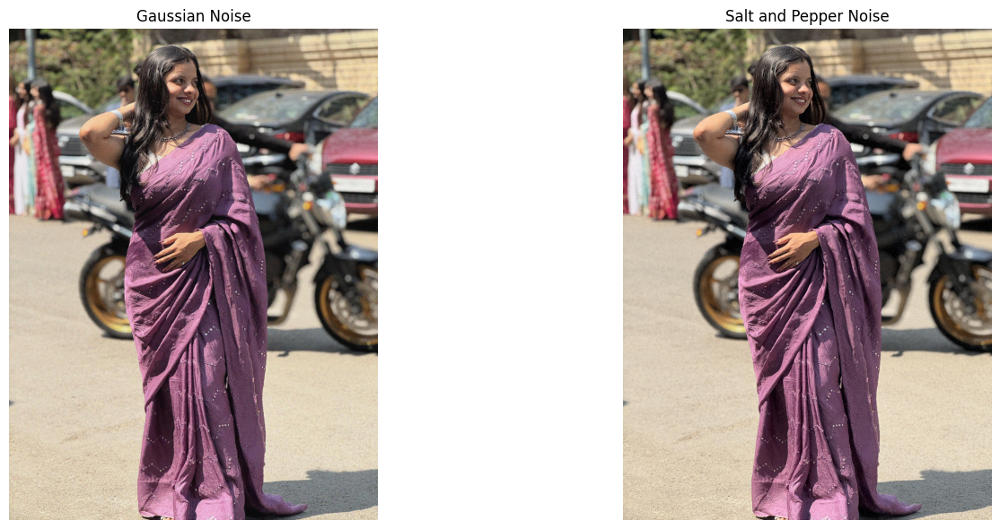

Gaussian noise added successfully!
Salt and Pepper noise added successfully!
Both images saved in Google Drive.


In [245]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Output folder
output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task1_image_restoration"

# 1. Add Gaussian Noise
mean = 0
sigma = 25

gaussian_noise = np.random.normal(
    mean, sigma, image.shape
)

gaussian_noisy = np.clip(
    image.astype(np.float32) + gaussian_noise,
    0, 255
).astype(np.uint8)


# 2. Add Salt and Pepper Noise
salt_pepper = image.copy()

height, width, channels = image.shape
probability = 0.02

random_values = np.random.random((height, width))

# Salt (white pixels)
salt_pepper[random_values < probability / 2] = 255

# Pepper (black pixels)
salt_pepper[
    (random_values >= probability / 2) &
    (random_values < probability)
] = 0


# Save noisy images
cv2.imwrite(
    os.path.join(output_path, "gaussian_noisy.jpg"),
    cv2.cvtColor(gaussian_noisy, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    os.path.join(output_path, "salt_pepper_noisy.jpg"),
    cv2.cvtColor(salt_pepper, cv2.COLOR_RGB2BGR)
)


# Display results
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.imshow(gaussian_noisy)
plt.title("Gaussian Noise")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(salt_pepper)
plt.title("Salt and Pepper Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Gaussian noise added successfully!")
print("Salt and Pepper noise added successfully!")
print("Both images saved in Google Drive.")

In [246]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

# Output folder
output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task1_image_restoration"

# 1. Median Filtering
median_gaussian = cv2.medianBlur(gaussian_noisy, 5)
median_salt_pepper = cv2.medianBlur(salt_pepper, 5)

# 2. Gaussian Filtering
gaussian_filtered_1 = cv2.GaussianBlur(gaussian_noisy, (5, 5), 1.5)
gaussian_filtered_2 = cv2.GaussianBlur(salt_pepper, (5, 5), 1.5)

# Save restored images
cv2.imwrite(
    os.path.join(output_path, "median_gaussian.jpg"),
    cv2.cvtColor(median_gaussian, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    os.path.join(output_path, "median_salt_pepper.jpg"),
    cv2.cvtColor(median_salt_pepper, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    os.path.join(output_path, "gaussian_filtered.jpg"),
    cv2.cvtColor(gaussian_filtered_1, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    os.path.join(output_path, "gaussian_filtered_salt_pepper.jpg"),
    cv2.cvtColor(gaussian_filtered_2, cv2.COLOR_RGB2BGR)
)

# Calculate PSNR and SSIM
results = {
    "Gaussian Noise - Original": gaussian_noisy,
    "Gaussian Noise - Median": median_gaussian,
    "Gaussian Noise - Gaussian Filter": gaussian_filtered_1,
    "Salt Pepper Noise - Original": salt_pepper,
    "Salt Pepper - Median": median_salt_pepper,
    "Salt Pepper - Gaussian Filter": gaussian_filtered_2
}

print("IMAGE RESTORATION PERFORMANCE")
print("-" * 65)

for name, restored in results.items():
    psnr = peak_signal_noise_ratio(image, restored, data_range=255)
    ssim = structural_similarity(
        image, restored, channel_axis=2, data_range=255
    )

    print(f"{name}")
    print(f"PSNR: {psnr:.2f} dB | SSIM: {ssim:.4f}")
    print("-" * 65)

print("All restoration results saved successfully!")

IMAGE RESTORATION PERFORMANCE
-----------------------------------------------------------------
Gaussian Noise - Original
PSNR: 20.48 dB | SSIM: 0.2245
-----------------------------------------------------------------
Gaussian Noise - Median
PSNR: 28.82 dB | SSIM: 0.7079
-----------------------------------------------------------------
Gaussian Noise - Gaussian Filter
PSNR: 29.80 dB | SSIM: 0.7639
-----------------------------------------------------------------
Salt Pepper Noise - Original
PSNR: 21.93 dB | SSIM: 0.5768
-----------------------------------------------------------------
Salt Pepper - Median
PSNR: 32.00 dB | SSIM: 0.9310
-----------------------------------------------------------------
Salt Pepper - Gaussian Filter
PSNR: 30.46 dB | SSIM: 0.8238
-----------------------------------------------------------------
All restoration results saved successfully!


Gryascale Image And Binary Image

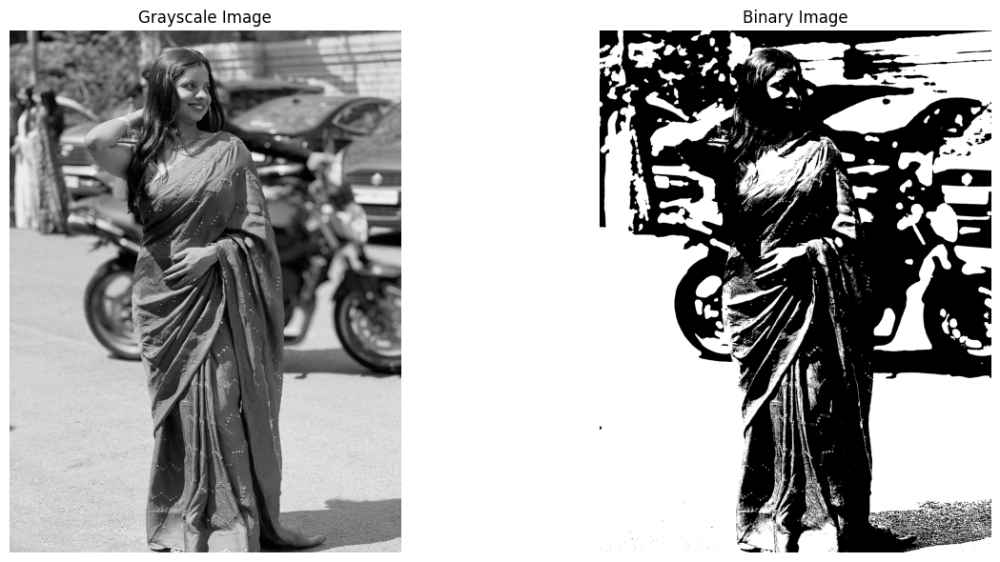

Binary thresholding completed!


In [247]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Output folder
output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task1_segmentation"

# Convert original image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Apply binary thresholding
_, binary = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

# Save binary image
cv2.imwrite(
    os.path.join(output_path, "binary_image.jpg"),
    binary
)

# Display results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Binary thresholding completed!")

Original Binary, Ersion, Dilation, Opening, Closing

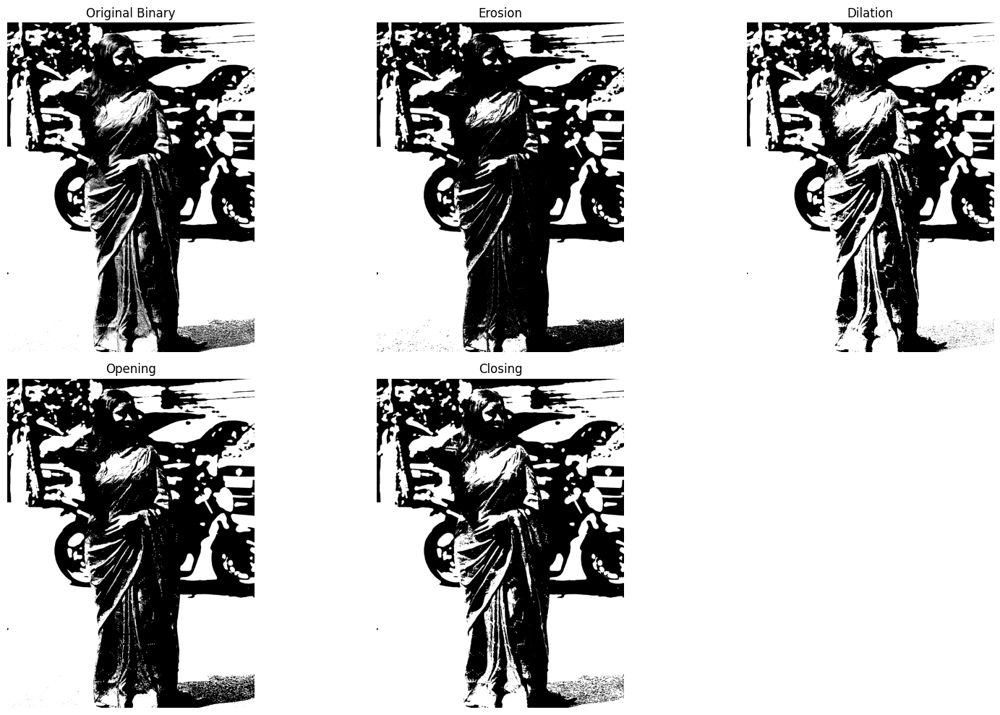

All four morphological operations completed!


In [248]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Create kernel
kernel = np.ones((5, 5), np.uint8)

# Morphological operations
erosion = cv2.erode(binary, kernel, iterations=1)

dilation = cv2.dilate(binary, kernel, iterations=1)

opening = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel
)

closing = cv2.morphologyEx(
    binary, cv2.MORPH_CLOSE, kernel
)

# Save results
output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task1_segmentation"

cv2.imwrite(os.path.join(output_path, "erosion.jpg"), erosion)
cv2.imwrite(os.path.join(output_path, "dilation.jpg"), dilation)
cv2.imwrite(os.path.join(output_path, "opening.jpg"), opening)
cv2.imwrite(os.path.join(output_path, "closing.jpg"), closing)

# Display results
plt.figure(figsize=(16, 10))

images = [
    (binary, "Original Binary"),
    (erosion, "Erosion"),
    (dilation, "Dilation"),
    (opening, "Opening"),
    (closing, "Closing")
]

for i, (img, title) in enumerate(images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("All four morphological operations completed!")

Canny Edge Image

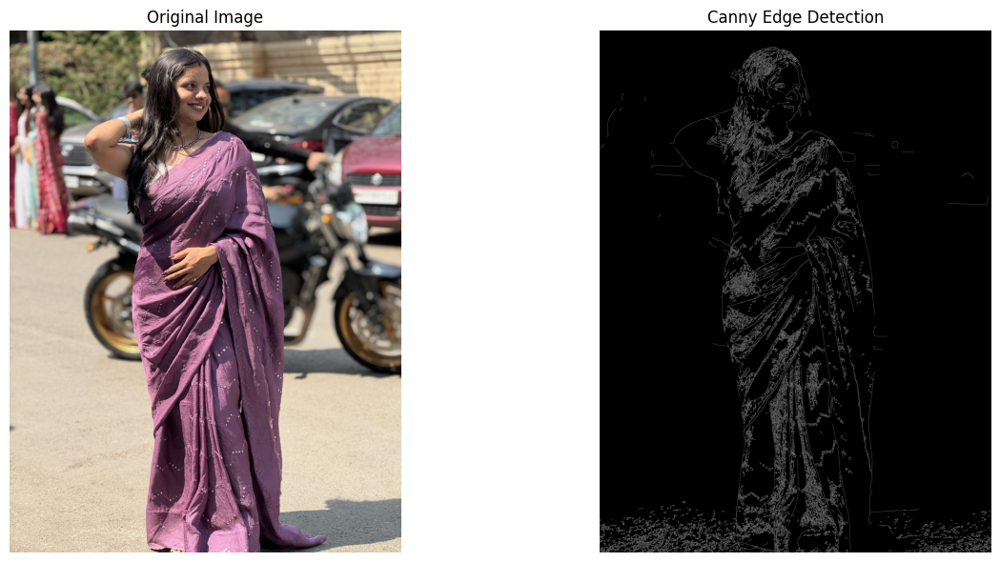

Canny Edge Detection completed successfully!


In [249]:
import cv2
import matplotlib.pyplot as plt
import os

output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task1_segmentation"

# Convert original image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Apply Gaussian blur to reduce noise
blurred = cv2.GaussianBlur(gray, (5, 5), 1.4)

# Apply Canny edge detection
edges = cv2.Canny(blurred, 50, 150)

# Save output
cv2.imwrite(
    os.path.join(output_path, "canny_edges.jpg"),
    edges
)

# Display results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Canny Edge Detection completed successfully!")

Watershed Segmentation

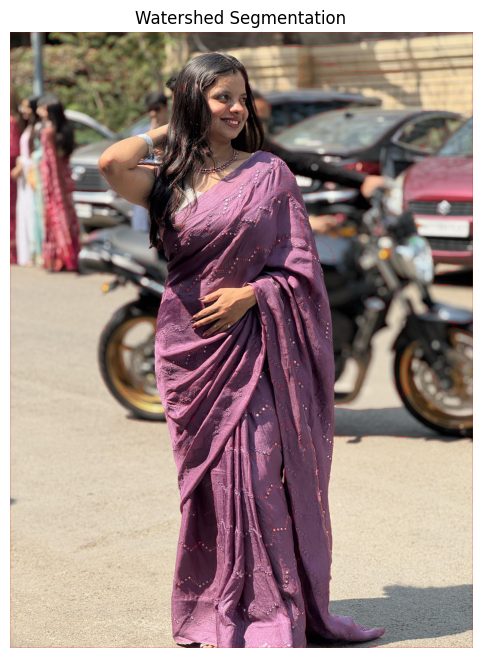

Watershed segmentation completed!
Number of identified regions: 56


In [250]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task1_segmentation"

# Convert RGB image to BGR
img = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Apply Otsu thresholding
_, thresh = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)
opening_ws = cv2.morphologyEx(
    thresh, cv2.MORPH_OPEN, kernel, iterations=2
)

# Sure background area
sure_bg = cv2.dilate(opening_ws, kernel, iterations=3)

# Distance transform
dist_transform = cv2.distanceTransform(
    opening_ws, cv2.DIST_L2, 5
)

# Sure foreground area
_, sure_fg = cv2.threshold(
    dist_transform,
    0.35 * dist_transform.max(),
    255,
    0
)

sure_fg = np.uint8(sure_fg)

# Unknown region
unknown = cv2.subtract(sure_bg, sure_fg)

# Create markers
_, markers = cv2.connectedComponents(sure_fg)

markers = markers + 1
markers[unknown == 255] = 0

# Apply watershed
markers = cv2.watershed(img, markers)

# Mark boundaries in red
result = img.copy()
result[markers == -1] = [0, 0, 255]

# Save result
cv2.imwrite(
    os.path.join(output_path, "watershed_result.jpg"),
    result
)

# Display result
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Watershed Segmentation")
plt.axis("off")
plt.show()

print("Watershed segmentation completed!")
print("Number of identified regions:", len(np.unique(markers)) - 1)

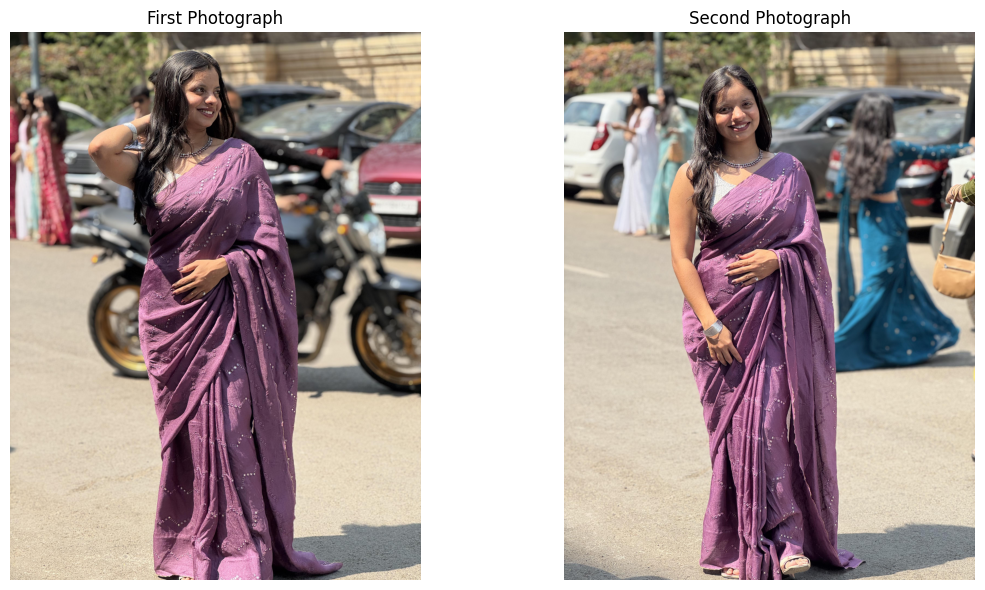

Both photographs loaded successfully!


In [251]:
import cv2
import matplotlib.pyplot as plt
import os

dataset_path = "/content/drive/MyDrive/CCA3_Computer_Vision/dataset"

# Load both photographs
photo1 = cv2.imread(
    os.path.join(dataset_path, "original_photo.jpg")
)

photo2 = cv2.imread(
    os.path.join(dataset_path, "second_photo.jpg")
)

# Convert BGR to RGB
photo1 = cv2.cvtColor(photo1, cv2.COLOR_BGR2RGB)
photo2 = cv2.cvtColor(photo2, cv2.COLOR_BGR2RGB)

# Display both photographs
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(photo1)
plt.title("First Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(photo2)
plt.title("Second Photograph")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Both photographs loaded successfully!")

HOG Features of 1&2 Photograph

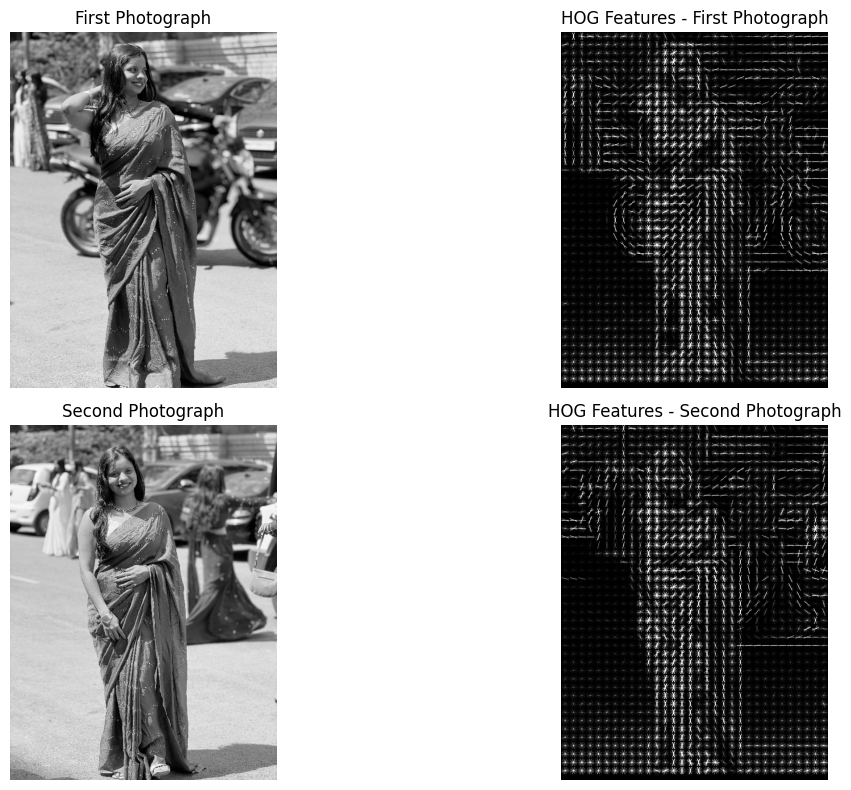

HOG feature extraction completed!
First photograph HOG features: 45756
Second photograph HOG features: 45756


In [252]:
from skimage.feature import hog
from skimage import exposure
import cv2
import matplotlib.pyplot as plt
import os

# Output folder
output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task2_feature_extraction"

# Convert photographs to grayscale
gray1 = cv2.cvtColor(photo1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(photo2, cv2.COLOR_RGB2GRAY)

# Resize images while maintaining aspect ratio
gray1 = cv2.resize(gray1, (512, 682))
gray2 = cv2.resize(gray2, (512, 682))

# Extract HOG features from first photograph
features1, hog_image1 = hog(
    gray1,
    orientations=9,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2),
    visualize=True
)

# Extract HOG features from second photograph
features2, hog_image2 = hog(
    gray2,
    orientations=9,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2),
    visualize=True
)

# Improve visualization contrast
hog_image1 = exposure.rescale_intensity(
    hog_image1, in_range=(0, 10)
)

hog_image2 = exposure.rescale_intensity(
    hog_image2, in_range=(0, 10)
)

# Save HOG visualizations
plt.imsave(
    os.path.join(output_path, "hog_first_photo.jpg"),
    hog_image1,
    cmap="gray"
)

plt.imsave(
    os.path.join(output_path, "hog_second_photo.jpg"),
    hog_image2,
    cmap="gray"
)

# Display results
plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray1, cmap="gray")
plt.title("First Photograph")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(hog_image1, cmap="gray")
plt.title("HOG Features - First Photograph")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(gray2, cmap="gray")
plt.title("Second Photograph")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(hog_image2, cmap="gray")
plt.title("HOG Features - Second Photograph")
plt.axis("off")

plt.tight_layout()
plt.show()

print("HOG feature extraction completed!")
print("First photograph HOG features:", len(features1))
print("Second photograph HOG features:", len(features2))

SIFT Keypoints of 1&2 Photograph

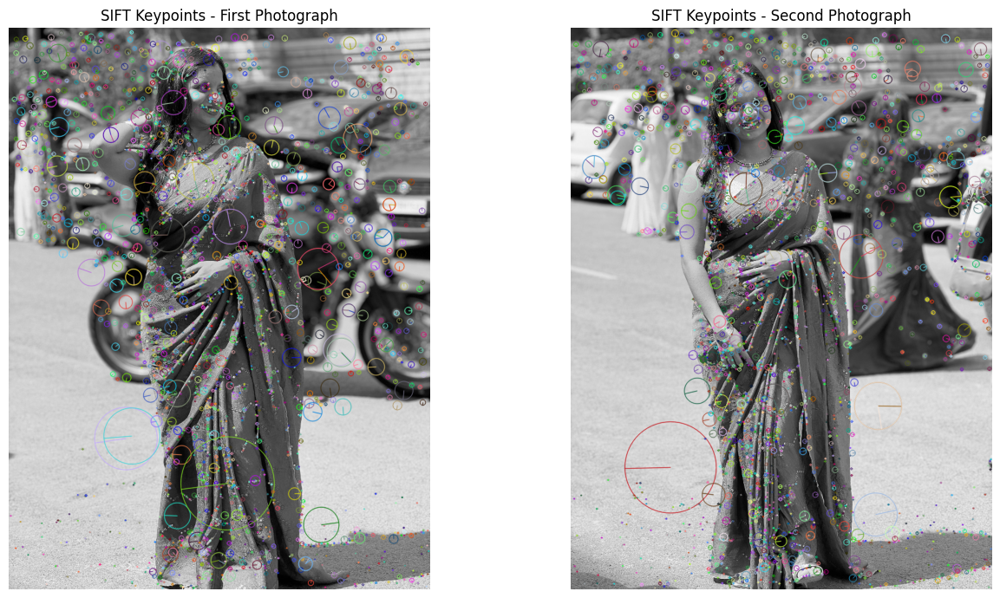

SIFT detection completed!
First photograph keypoints: 2639
Second photograph keypoints: 2677
First descriptors: (2639, 128)
Second descriptors: (2677, 128)


In [253]:
import cv2
import matplotlib.pyplot as plt
import os

output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task2_feature_extraction"

# Convert RGB to grayscale
gray1 = cv2.cvtColor(photo1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(photo2, cv2.COLOR_RGB2GRAY)

# Resize images
gray1 = cv2.resize(gray1, (800, 1067))
gray2 = cv2.resize(gray2, (800, 1067))

# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and calculate descriptors
keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

# Draw keypoints
sift_image1 = cv2.drawKeypoints(
    gray1, keypoints1, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

sift_image2 = cv2.drawKeypoints(
    gray2, keypoints2, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Save results
cv2.imwrite(
    os.path.join(output_path, "sift_first_photo.jpg"),
    sift_image1
)

cv2.imwrite(
    os.path.join(output_path, "sift_second_photo.jpg"),
    sift_image2
)

# Display results
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(sift_image1, cv2.COLOR_BGR2RGB))
plt.title("SIFT Keypoints - First Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sift_image2, cv2.COLOR_BGR2RGB))
plt.title("SIFT Keypoints - Second Photograph")
plt.axis("off")

plt.tight_layout()
plt.show()

print("SIFT detection completed!")
print("First photograph keypoints:", len(keypoints1))
print("Second photograph keypoints:", len(keypoints2))
print("First descriptors:", descriptors1.shape)
print("Second descriptors:", descriptors2.shape)

SIFT Feature Matching 1&2 Photograph

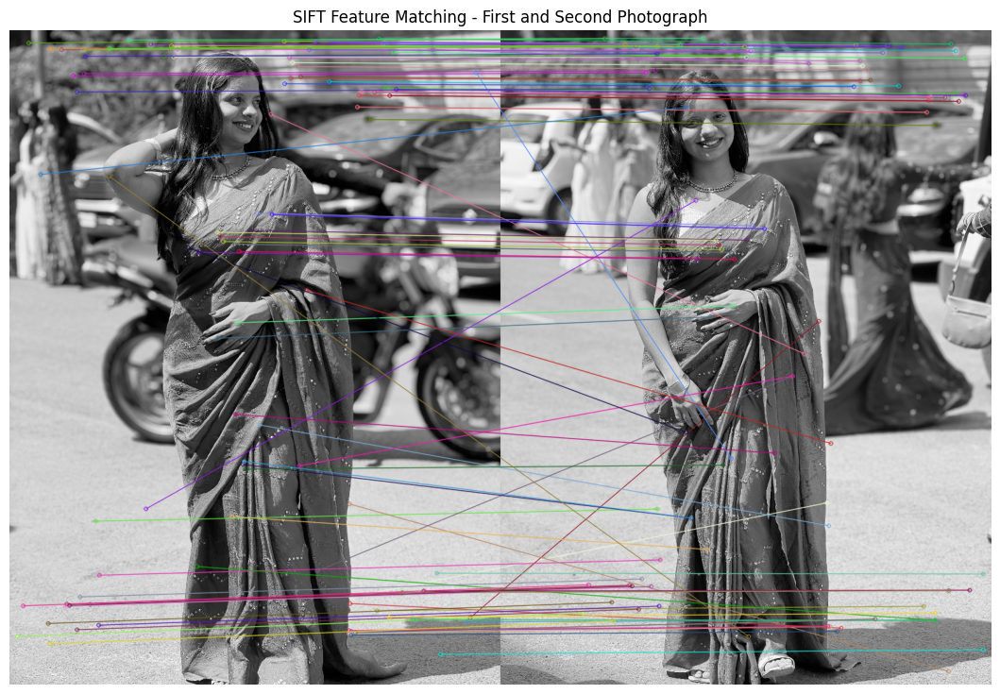

SIFT feature matching completed!
Total KNN matches: 2639
Good matches after ratio test: 109


In [254]:
import cv2
import matplotlib.pyplot as plt
import os

output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task2_feature_extraction"

# Create Brute Force Matcher
bf = cv2.BFMatcher()

# KNN matching
matches = bf.knnMatch(
    descriptors1,
    descriptors2,
    k=2
)

# Apply Lowe's Ratio Test
good_matches = []

for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

# Sort matches by distance
good_matches = sorted(
    good_matches,
    key=lambda x: x.distance
)

# Draw best matches
matching_image = cv2.drawMatches(
    gray1, keypoints1,
    gray2, keypoints2,
    good_matches[:100],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Save result
cv2.imwrite(
    os.path.join(output_path, "sift_feature_matching.jpg"),
    matching_image
)

# Display result
plt.figure(figsize=(18, 9))
plt.imshow(matching_image, cmap="gray")
plt.title("SIFT Feature Matching - First and Second Photograph")
plt.axis("off")
plt.show()

print("SIFT feature matching completed!")
print("Total KNN matches:", len(matches))
print("Good matches after ratio test:", len(good_matches))

Matching after Rotation and Resizing

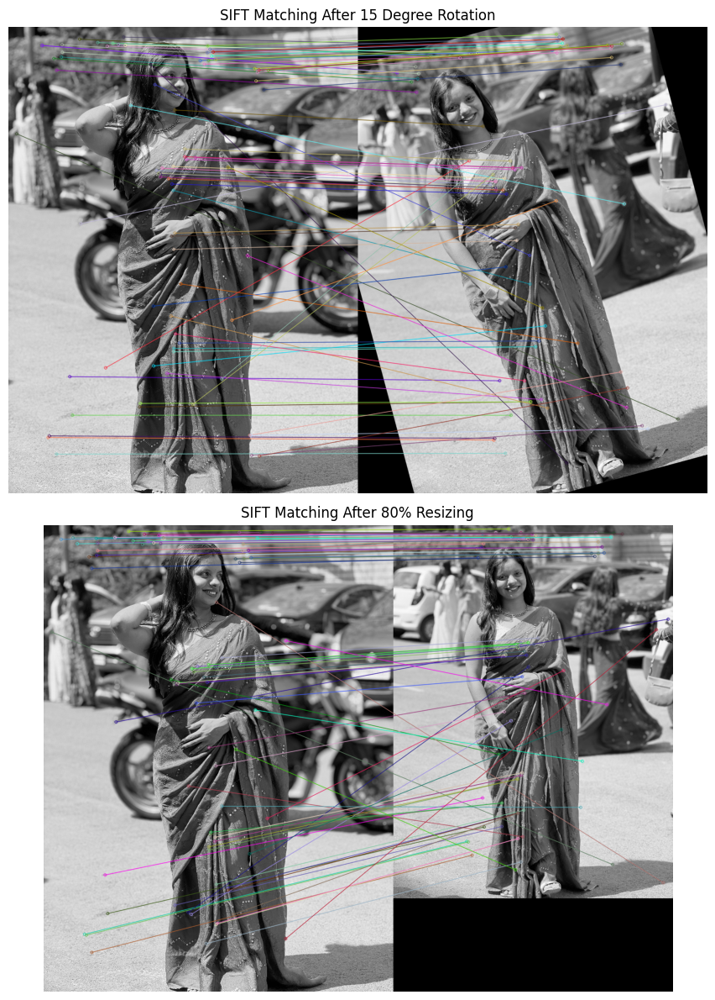

FEATURE MATCHING COMPARISON
--------------------------------
Original good matches: 109
After rotation: 91
After resizing: 100
--------------------------------
Rotation and resizing experiments completed!


In [255]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task2_feature_extraction"

# Create SIFT detector
sift = cv2.SIFT_create()

# Create matcher
bf = cv2.BFMatcher()

# Function for feature matching
def match_features(img1, img2):

    kp1, des1 = sift.detectAndCompute(img1, None)
    kp2, des2 = sift.detectAndCompute(img2, None)

    matches = bf.knnMatch(des1, des2, k=2)

    good = []

    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good.append(m)

    return kp1, kp2, good


# FIRST IMAGE
base_image = gray1.copy()


# EXPERIMENT 1: ROTATION
h, w = gray2.shape

matrix = cv2.getRotationMatrix2D(
    (w // 2, h // 2), 15, 1.0
)

rotated_image = cv2.warpAffine(
    gray2, matrix, (w, h)
)


# EXPERIMENT 2: RESIZING
resized_image = cv2.resize(
    gray2, None, fx=0.8, fy=0.8
)


# Match rotated image
kp1, kp_rotated, matches_rotated = match_features(
    base_image, rotated_image
)

# Match resized image
kp1_resize, kp_resized, matches_resized = match_features(
    base_image, resized_image
)


# Draw rotation matches
rotation_result = cv2.drawMatches(
    base_image, kp1,
    rotated_image, kp_rotated,
    matches_rotated[:80],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Draw resizing matches
resize_result = cv2.drawMatches(
    base_image, kp1_resize,
    resized_image, kp_resized,
    matches_resized[:80],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)


# Save results
cv2.imwrite(
    os.path.join(output_path, "rotation_matching.jpg"),
    rotation_result
)

cv2.imwrite(
    os.path.join(output_path, "resize_matching.jpg"),
    resize_result
)


# Display results
plt.figure(figsize=(18, 12))

plt.subplot(2, 1, 1)
plt.imshow(rotation_result, cmap="gray")
plt.title("SIFT Matching After 15 Degree Rotation")
plt.axis("off")

plt.subplot(2, 1, 2)
plt.imshow(resize_result, cmap="gray")
plt.title("SIFT Matching After 80% Resizing")
plt.axis("off")

plt.tight_layout()
plt.show()


# Print comparison
print("FEATURE MATCHING COMPARISON")
print("--------------------------------")

print("Original good matches:", len(good_matches))
print("After rotation:", len(matches_rotated))
print("After resizing:", len(matches_resized))

print("--------------------------------")
print("Rotation and resizing experiments completed!")

 Task 3- Viola–Jones Face Detection

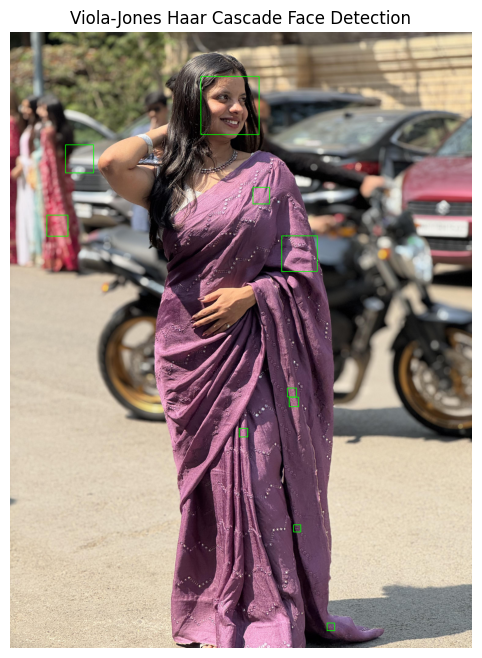

Haar Cascade detection completed!
Number of faces detected: 10


In [256]:
import cv2
import matplotlib.pyplot as plt
import os

# Output folder
output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task3_object_detection"

# Load original photograph
photo = cv2.imread(
    "/content/drive/MyDrive/CCA3_Computer_Vision/dataset/original_photo.jpg"
)

# Convert to grayscale
gray = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)

# Load pretrained Haar Cascade classifier
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

# Detect faces
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

# Draw bounding boxes
result = photo.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

# Save output
cv2.imwrite(
    os.path.join(output_path, "haar_face_detection.jpg"),
    result
)

# Display result
plt.figure(figsize=(10, 8))

plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Viola-Jones Haar Cascade Face Detection")
plt.axis("off")
plt.show()

print("Haar Cascade detection completed!")
print("Number of faces detected:", len(faces))

Improve Haar Cascade detection

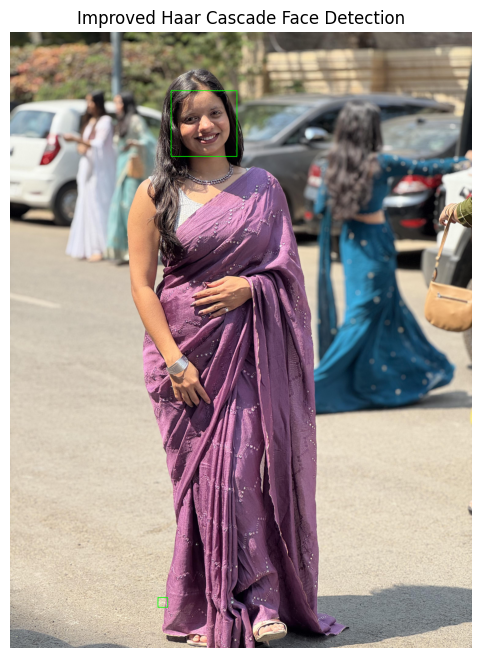

Improved Haar Cascade detection completed!
Faces detected: 2


In [257]:
import cv2
import matplotlib.pyplot as plt
import os

output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task3_object_detection"

# Load second photograph
photo = cv2.imread(
    "/content/drive/MyDrive/CCA3_Computer_Vision/dataset/second_photo.jpg"
)

gray = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)

# Load Haar Cascade
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

# Detect faces with stricter parameters
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=8,
    minSize=(60, 60)
)

# Draw bounding boxes
result = photo.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

# Save result
cv2.imwrite(
    os.path.join(output_path, "haar_face_detection_improved.jpg"),
    result
)

# Display
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Improved Haar Cascade Face Detection")
plt.axis("off")
plt.show()

print("Improved Haar Cascade detection completed!")
print("Faces detected:", len(faces))


image 1/1 /content/drive/MyDrive/CCA3_Computer_Vision/dataset/second_photo.jpg: 640x480 5 persons, 3 cars, 168.2ms
Speed: 4.1ms preprocess, 168.2ms inference, 2.6ms postprocess per image at shape (1, 3, 640, 480)


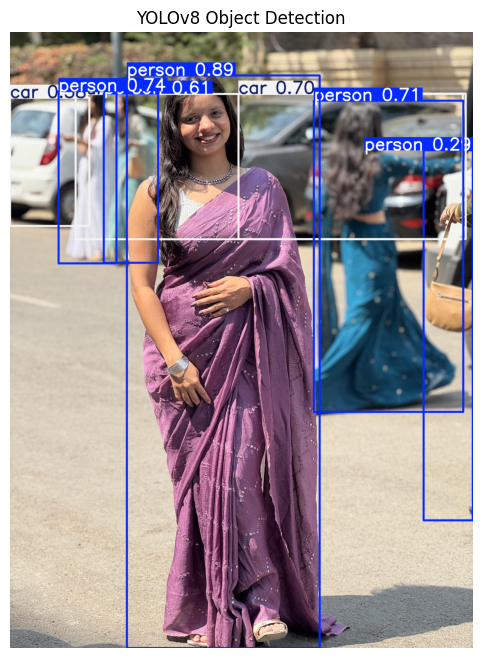

YOLO Object Detection Results:
--------------------------------
person - Confidence: 88.81 %
person - Confidence: 73.66 %
person - Confidence: 70.66 %
car - Confidence: 69.94 %
person - Confidence: 61.07 %
car - Confidence: 58.17 %
car - Confidence: 33.25 %
person - Confidence: 28.83 %
YOLO detection completed successfully!


In [258]:
!pip install -q ultralytics

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import os

# Output folder
output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task3_object_detection"

# Load YOLOv8 Nano pretrained model
model = YOLO("yolov8n.pt")

# Load second photograph
image_path = "/content/drive/MyDrive/CCA3_Computer_Vision/dataset/second_photo.jpg"

# Perform object detection
results = model(image_path, conf=0.25)

# Display and save detection result
for result in results:

    annotated_image = result.plot()

    cv2.imwrite(
        os.path.join(output_path, "yolo_object_detection.jpg"),
        annotated_image
    )

    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
    plt.title("YOLOv8 Object Detection")
    plt.axis("off")
    plt.show()

    print("YOLO Object Detection Results:")
    print("--------------------------------")

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        print(
            model.names[class_id],
            "- Confidence:",
            round(confidence * 100, 2),
            "%"
        )

print("YOLO detection completed successfully!")

Compare Haar Cascade and YOLO

In [259]:
import pandas as pd
import matplotlib.pyplot as plt

# Comparison data
comparison = pd.DataFrame({
    "Parameter": [
        "Detection Method",
        "Main Purpose",
        "Detections",
        "Multiple Object Classes",
        "Confidence Scores",
        "False Detections"
    ],

    "Haar Cascade": [
        "Viola-Jones",
        "Face Detection",
        "2",
        "No",
        "No",
        "1 observed"
    ],

    "YOLOv8": [
        "Deep Learning",
        "Object Detection",
        "8",
        "Yes",
        "Yes",
        "Some inaccurate boxes"
    ]
})

print("HAAR CASCADE VS YOLO COMPARISON")
display(comparison)

# Save comparison
comparison.to_csv(
    "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task3_object_detection/comparison.csv",
    index=False
)

print("Comparison saved successfully!")

HAAR CASCADE VS YOLO COMPARISON


,Parameter,Haar Cascade,YOLOv8
0,Detection Method,Viola-Jones,Deep Learning
1,Main Purpose,Face Detection,Object Detection
2,Detections,2,8
3,Multiple Object Classes,No,Yes
4,Confidence Scores,No,Yes
5,False Detections,1 observed,Some inaccurate boxes


Comparison saved successfully!


Task-4

In [260]:
import cv2
import os
import matplotlib.pyplot as plt

# Video path
video_path = "/content/drive/MyDrive/CCA3_Computer_Vision/dataset/Cv video.MOV"

# Open video
cap = cv2.VideoCapture(video_path)

if cap.isOpened():

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    duration = total_frames / fps

    print("Video loaded successfully!")
    print("Resolution:", width, "x", height)
    print("FPS:", fps)
    print("Total frames:", total_frames)
    print("Duration:", round(duration, 2), "seconds")

else:
    print("Error: Video could not be opened!")

cap.release()

Video loaded successfully!
Resolution: 1080 x 1920
FPS: 29.99345121152587
Total frames: 229
Duration: 7.63 seconds


Extract consecutive video frames

Frame extraction completed!
Total video frames: 229
Extracted frames: 46


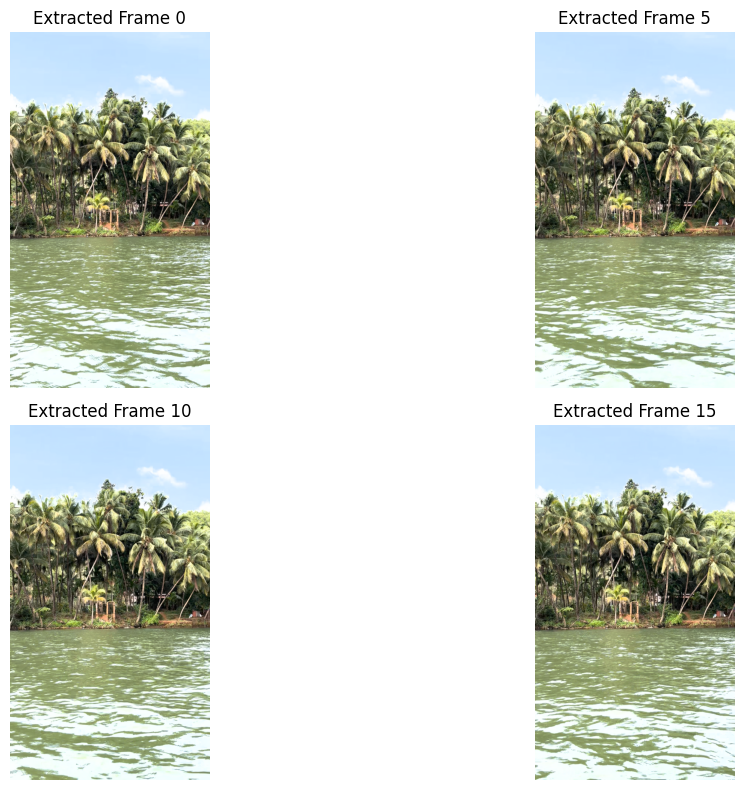

In [261]:
import cv2
import os
import matplotlib.pyplot as plt

# Video path
video_path = "/content/drive/MyDrive/CCA3_Computer_Vision/dataset/Cv video.MOV"

# Create output folder
frame_folder = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task4_motion_estimation/frames"
os.makedirs(frame_folder, exist_ok=True)

# Open video
cap = cv2.VideoCapture(video_path)

# Extract frames
frames = []
frame_count = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    if frame_count % 5 == 0:
        frames.append(frame.copy())

        cv2.imwrite(
            os.path.join(frame_folder, f"frame_{frame_count}.jpg"),
            frame
        )

    frame_count += 1

cap.release()

print("Frame extraction completed!")
print("Total video frames:", frame_count)
print("Extracted frames:", len(frames))

# Display first four extracted frames
plt.figure(figsize=(14, 8))

for i in range(min(4, len(frames))):
    plt.subplot(2, 2, i + 1)
    plt.imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB))
    plt.title(f"Extracted Frame {i * 5}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Frame Differencing

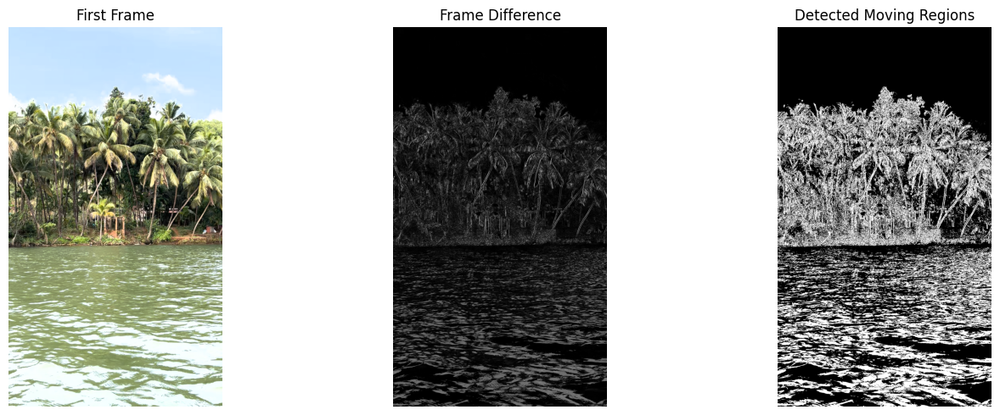

Frame differencing completed successfully!
Motion pixels detected: 735950


In [262]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Video path
video_path = "/content/drive/MyDrive/CCA3_Computer_Vision/dataset/Cv video.MOV"

# Output folder
output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task4_motion_estimation"

os.makedirs(output_path, exist_ok=True)

# Open video
cap = cv2.VideoCapture(video_path)

# Read first frame
ret, frame1 = cap.read()

# Read second frame
ret, frame2 = cap.read()

# Convert frames to grayscale
gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)

# Calculate absolute difference
difference = cv2.absdiff(gray1, gray2)

# Apply threshold
_, motion_mask = cv2.threshold(
    difference, 20, 255, cv2.THRESH_BINARY
)

# Save results
cv2.imwrite(
    os.path.join(output_path, "frame_difference.jpg"),
    difference
)

cv2.imwrite(
    os.path.join(output_path, "motion_mask.jpg"),
    motion_mask
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB))
plt.title("First Frame")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(difference, cmap="gray")
plt.title("Frame Difference")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(motion_mask, cmap="gray")
plt.title("Detected Moving Regions")
plt.axis("off")

plt.tight_layout()
plt.show()

cap.release()

print("Frame differencing completed successfully!")
print("Motion pixels detected:", np.count_nonzero(motion_mask))

GMM Background Subtraction

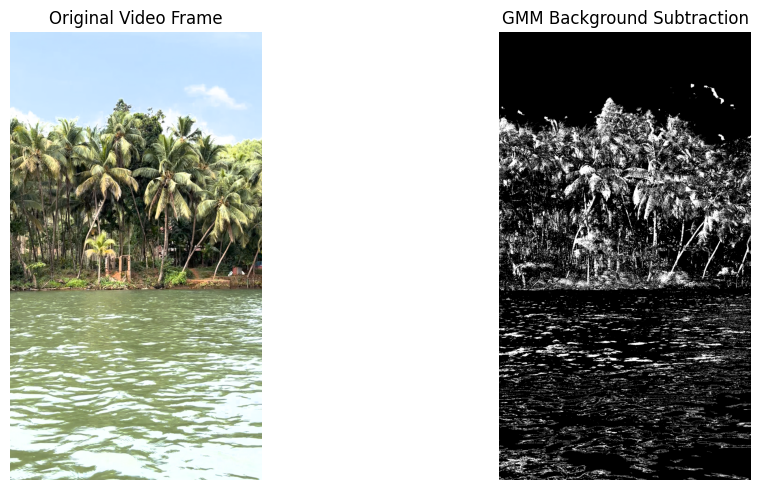

GMM Background Subtraction completed!
Total frames processed: 229


In [263]:
import cv2
import matplotlib.pyplot as plt
import os

video_path = "/content/drive/MyDrive/CCA3_Computer_Vision/dataset/Cv video.MOV"

output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task4_motion_estimation"

os.makedirs(output_path, exist_ok=True)

# Open video
cap = cv2.VideoCapture(video_path)

# Create GMM background subtractor
backSub = cv2.createBackgroundSubtractorMOG2(
    history=100,
    varThreshold=50,
    detectShadows=True
)

frame_count = 0
motion_frame = None
original_frame = None

while True:
    ret, frame = cap.read()

    if not ret:
        break

    # Apply background subtraction
    fgMask = backSub.apply(frame)

    frame_count += 1

    # Store a sample frame
    if frame_count == 50:
        motion_frame = fgMask.copy()
        original_frame = frame.copy()

cap.release()

# Save results
cv2.imwrite(
    os.path.join(output_path, "gmm_motion_mask.jpg"),
    motion_frame
)

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(original_frame, cv2.COLOR_BGR2RGB))
plt.title("Original Video Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(motion_frame, cmap="gray")
plt.title("GMM Background Subtraction")
plt.axis("off")

plt.tight_layout()
plt.show()

print("GMM Background Subtraction completed!")
print("Total frames processed:", frame_count)

Optical Flow (Motion Tracking)

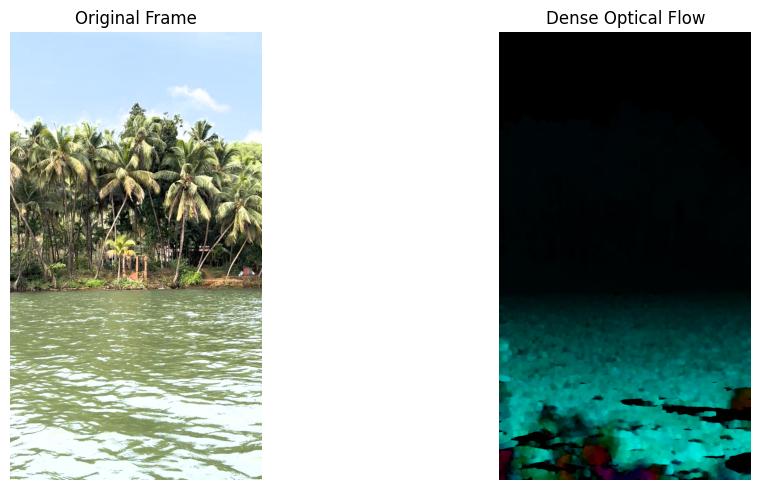

Optical Flow completed successfully!
Average motion magnitude: 13.359


In [264]:
import cv2
import matplotlib.pyplot as plt
import os

video_path = "/content/drive/MyDrive/CCA3_Computer_Vision/dataset/Cv video.MOV"

output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task4_motion_estimation"

cap = cv2.VideoCapture(video_path)

ret, frame1 = cap.read()
ret, frame2 = cap.read()

prvs = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
next_frame = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)

# Calculate dense optical flow
flow = cv2.calcOpticalFlowFarneback(
    prvs, next_frame, None,
    0.5, 3, 15, 3, 5, 1.2, 0
)

# Convert flow into magnitude and angle
magnitude, angle = cv2.cartToPolar(
    flow[..., 0], flow[..., 1]
)

# Create HSV visualization
hsv = cv2.cvtColor(frame1, cv2.COLOR_BGR2HSV)
hsv[..., 0] = angle * 180 / 3.14159 / 2
hsv[..., 1] = 255
hsv[..., 2] = cv2.normalize(
    magnitude, None, 0, 255, cv2.NORM_MINMAX
)

optical_flow = cv2.cvtColor(
    hsv, cv2.COLOR_HSV2RGB
)

# Save result
cv2.imwrite(
    os.path.join(output_path, "optical_flow.jpg"),
    cv2.cvtColor(optical_flow, cv2.COLOR_RGB2BGR)
)

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB))
plt.title("Original Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(optical_flow)
plt.title("Dense Optical Flow")
plt.axis("off")

plt.tight_layout()
plt.show()

cap.release()

print("Optical Flow completed successfully!")
print("Average motion magnitude:", round(float(magnitude.mean()), 3))

Motion Detection Using Contours

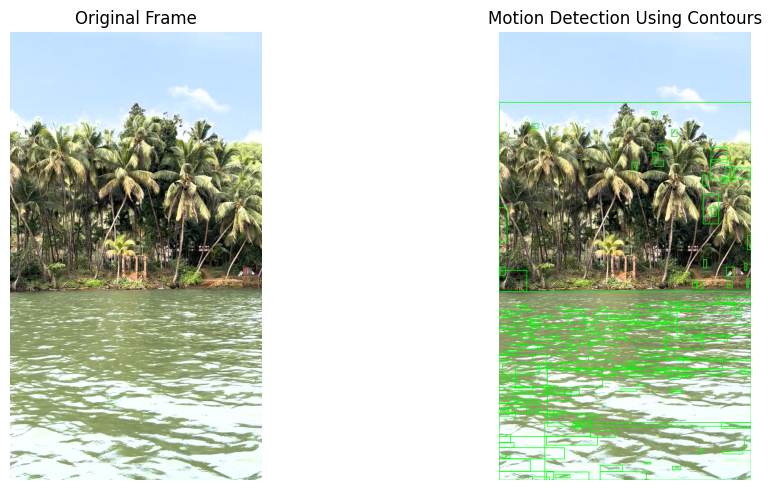

Motion detection using contours completed!
Moving regions detected: 190


In [265]:
import cv2
import matplotlib.pyplot as plt
import os

video_path = "/content/drive/MyDrive/CCA3_Computer_Vision/dataset/Cv video.MOV"

output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task4_motion_estimation"

cap = cv2.VideoCapture(video_path)

ret, frame1 = cap.read()
ret, frame2 = cap.read()

gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)

# Calculate frame difference
diff = cv2.absdiff(gray1, gray2)

# Apply threshold
_, thresh = cv2.threshold(diff, 25, 255, cv2.THRESH_BINARY)

# Find contours
contours, _ = cv2.findContours(
    thresh,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

result = frame2.copy()

motion_count = 0

for contour in contours:
    if cv2.contourArea(contour) > 100:
        x, y, w, h = cv2.boundingRect(contour)

        cv2.rectangle(
            result,
            (x, y),
            (x+w, y+h),
            (0, 255, 0),
            2
        )

        motion_count += 1

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(frame2, cv2.COLOR_BGR2RGB))
plt.title("Original Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Motion Detection Using Contours")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save result
cv2.imwrite(
    os.path.join(output_path, "motion_contours.jpg"),
    result
)

cap.release()

print("Motion detection using contours completed!")
print("Moving regions detected:", motion_count)

Save Motion Detection Results

In [266]:
import pandas as pd
import os

output_path = "/content/drive/MyDrive/CCA3_Computer_Vision/outputs/task4_motion_estimation"

results = pd.DataFrame({
    "Technique": [
        "Frame Differencing",
        "GMM Background Subtraction",
        "Dense Optical Flow",
        "Contour-Based Motion Detection"
    ],
    "Result": [
        "Completed",
        "Completed",
        "Completed",
        "Completed"
    ],
    "Observations": [
        "735950 motion pixels detected",
        "229 video frames processed",
        "Average motion magnitude: 13.359",
        "190 moving regions detected"
    ]
})

print("MOTION DETECTION PERFORMANCE SUMMARY")
display(results)

results.to_csv(
    os.path.join(output_path, "motion_detection_summary.csv"),
    index=False
)

print("Motion detection summary saved successfully!")

MOTION DETECTION PERFORMANCE SUMMARY


,Technique,Result,Observations
0,Frame Differencing,Completed,735950 motion pixels detected
1,GMM Background Subtraction,Completed,229 video frames processed
2,Dense Optical Flow,Completed,Average motion magnitude: 13.359
3,Contour-Based Motion Detection,Completed,190 moving regions detected


Motion detection summary saved successfully!
